# 02 — Forecasting tonight: dome closure, seeing and hours lost

**Independent project, not affiliated with GRANTECAN or any observatory.** All data are real and public.
Inputs known at the start of the night: the ECMWF IFS HRES forecast (Open-Meteo archive), the NOT station
in the 2 hours before the night, last night's outcome and the time of year (`src/roque_forecast/features.py`).

Train 2017–2022, choose settings on 2023, **test on 2024–2026** (never seen by any step). Every model is
compared with reference methods it must beat: climatology, persistence and precasting.
Built with `python -m roque_forecast.features` and `python -m roque_forecast.train`.

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from roque_forecast import config, plotting

plotting.apply_style()
BLUE, ORANGE, AQUA, YELLOW = plotting.SERIES[:4]
RESULTS = config.PROJECT_DIR / "reports" / "results"
closure = pd.read_csv(RESULTS / "closure_metrics.csv")
seeing = pd.read_csv(RESULTS / "seeing_metrics.csv")
lost = pd.read_csv(RESULTS / "lost_hours_metrics.csv")
predictions = pd.read_parquet(config.PROCESSED_DIR / "predictions.parquet")
test = predictions[predictions["split"] == "test"]
print(json.loads((RESULTS / "settings.json").read_text()))

{'closure': {'learning_rate': 0.03, 'max_leaf_nodes': 7, 'min_samples_leaf': 20}, 'closure_calibration_check': {'full': {'brier_raw': 0.0517, 'brier_isotonic': 0.0521, 'apply': False}, 'forecast_only': {'brier_raw': 0.0922, 'brier_isotonic': 0.0933, 'apply': False}}, 'lost_hours_slope': 0.849, 'train_years': [2017, 2022], 'validation_year': 2023, 'test_from': '2024-01-01'}


In [2]:
def skill_bars(ax, frame, column, title, xlabel):
    """Horizontal bars, one per method; models in blue, baselines in grey."""
    frame = frame.iloc[::-1]
    colors = [BLUE if kind == "model" else plotting.GRID for kind in frame["kind"]]
    ax.barh(frame["method"], frame[column], color=colors, height=0.6)
    for y, value in enumerate(frame[column]):
        ax.annotate(f"{value:.2f}", (max(value, 0), y), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=plotting.TEXT_SECONDARY)
    ax.axvline(0, color=plotting.TEXT_SECONDARY, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)

## 1. Dome closure risk

Label: the humidity rule (close at ≥ 90 %, reopen after 20 min below) closes the dome for at least 1 hour.
About 1 night in 5. Scores: **Brier** (mean squared error of the probability; lower is better) and
**Brier skill** against climatology (0 = no better than "the usual for this month", 1 = perfect).

In [3]:
closure[["inputs", "method", "nights", "brier", "brier_skill_vs_climatology", "auc", "hit_rate", "false_alarm_ratio"]]

,inputs,method,nights,brier,brier_skill_vs_climatology,auc,hit_rate,false_alarm_ratio
0,forecast archive,climatology (month),1025,0.1490,0.0000,0.7014,0.0000,NaN
1,forecast archive,persistence (last night),1025,0.1308,0.1219,0.7237,0.5592,0.4354
2,forecast archive,precasting (humidity before night >= 90 %),1025,0.0816,0.4524,0.8340,0.7062,0.1722
3,forecast archive,forecast rule (forecast humidity >= 95 %),1025,0.1526,-0.0242,0.6373,0.0000,NaN
4,forecast archive,gradient boosting,1025,0.0670,0.5504,0.9582,0.7915,0.2511
5,forecast archive,logistic regression,1025,0.0775,0.4796,0.9448,0.7773,0.2679
6,forecast archive,"gradient boosting, forecast only",1025,0.0943,0.3673,0.9138,0.6825,0.3333
7,24 h old forecast,climatology (month),398,0.1695,0.0000,0.6717,0.0000,NaN
8,24 h old forecast,persistence (last night),398,0.1444,0.1481,0.7268,0.5789,0.4086
9,24 h old forecast,precasting (humidity before night >= 90 %),398,0.0941,0.4445,0.8295,0.7053,0.1728


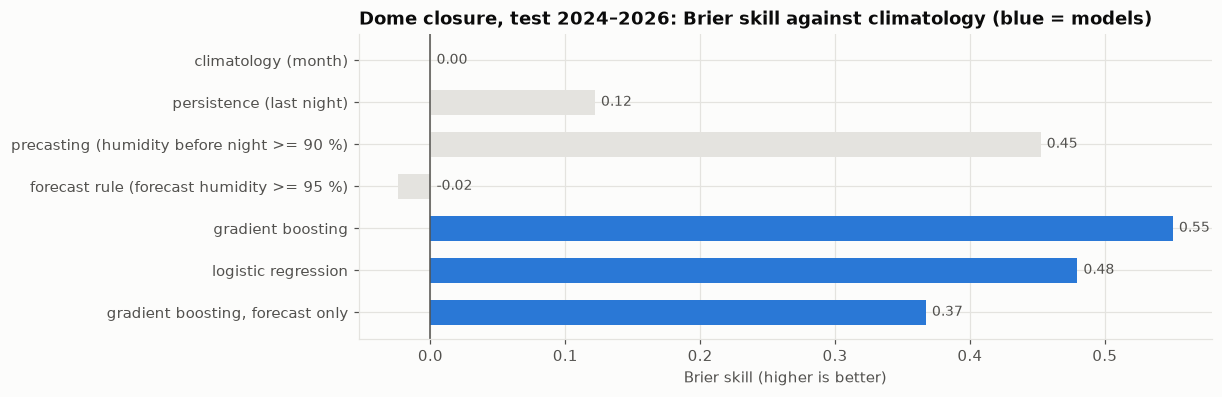

In [4]:
fig, ax = plt.subplots(figsize=(10, 3.6))
skill_bars(ax, closure[closure["inputs"] == "forecast archive"], "brier_skill_vs_climatology",
           "Dome closure, test 2024–2026: Brier skill against climatology (blue = models)",
           "Brier skill (higher is better)")
plotting.save(fig, "06_closure_skill")

Is a predicted "30 %" really closed 30 % of the time? The **reliability diagram** groups the test nights by
predicted probability and compares with how often the dome really closed. On the diagonal = trustworthy.

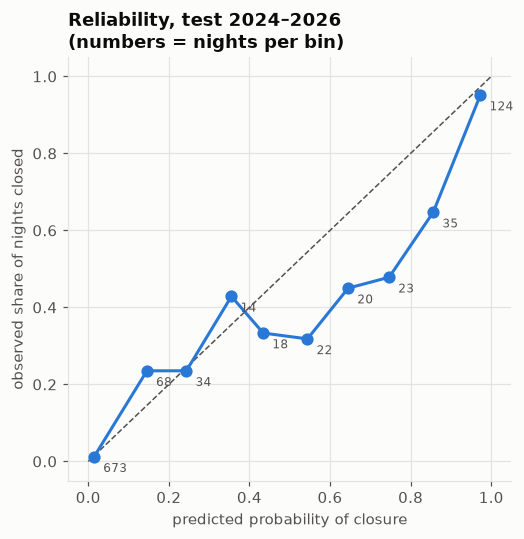

In [5]:
bins = np.linspace(0, 1, 11)
groups = pd.cut(test["p_closed"], bins, include_lowest=True)
reliability = test.groupby(groups, observed=True).agg(predicted=("p_closed", "mean"),
                                                      observed=("closed", "mean"), nights=("closed", "size"))
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=plotting.TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.plot(reliability["predicted"], reliability["observed"], color=BLUE, marker="o", markersize=7)
for _, row in reliability.iterrows():
    ax.annotate(f"{row['nights']:.0f}", (row["predicted"], row["observed"]), xytext=(6, -10),
                textcoords="offset points", fontsize=8, color=plotting.TEXT_SECONDARY)
ax.set_xlabel("predicted probability of closure")
ax.set_ylabel("observed share of nights closed")
ax.set_title("Reliability, test 2024–2026\n(numbers = nights per bin)")
plotting.save(fig, "07_closure_reliability")

Which inputs matter? **Permutation importance**: shuffle one input on the test nights and measure how much
the Brier score worsens.

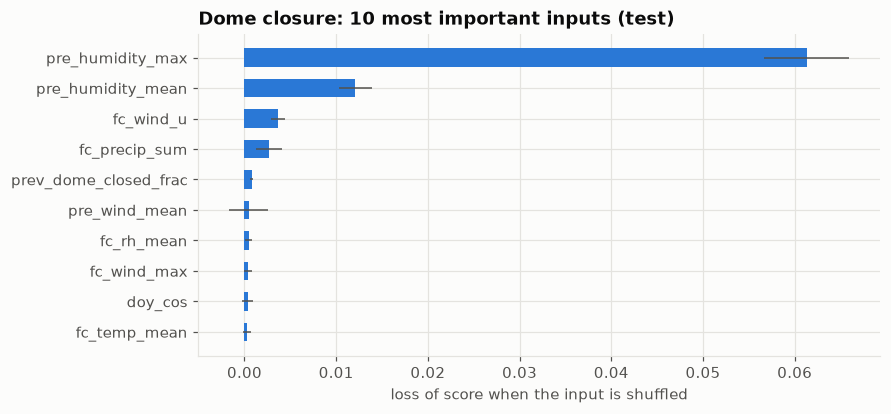

In [6]:
def importance_plot(name, title, figure):
    imp = pd.read_csv(RESULTS / f"{name}_importance.csv").head(10).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.barh(imp["feature"], imp["importance"], xerr=imp["std"], color=BLUE, height=0.6,
            error_kw={"ecolor": plotting.TEXT_SECONDARY, "linewidth": 1})
    ax.set_title(title)
    ax.set_xlabel("loss of score when the input is shuffled")
    plotting.save(fig, figure)


importance_plot("closure", "Dome closure: 10 most important inputs (test)", "08_closure_importance")

## 2. Seeing

Label: median R2D2 seeing of the night (arcsec). Scores: RMSE (root mean squared error, in arcsec) and
skill against climatology. Persistence is worse than climatology here: one night's turbulence says
little about the next.

In [7]:
seeing[["inputs", "method", "nights", "rmse", "mae", "rmse_skill_vs_climatology"]]

,inputs,method,nights,rmse,mae,rmse_skill_vs_climatology
0,forecast archive,climatology (month),780,0.3500,0.2272,0.0000
1,forecast archive,persistence (last night),780,0.4149,0.2779,-0.1855
2,forecast archive,gradient boosting,780,0.2844,0.1967,0.1873
3,forecast archive,"gradient boosting, no jet stream",780,0.2859,0.1981,0.1831
4,forecast archive,linear regression,780,0.2879,0.2024,0.1773
5,forecast archive,"gradient boosting, forecast only",780,0.3101,0.2185,0.1139
6,24 h old forecast,climatology (month),324,0.3780,0.2453,0.0000
7,24 h old forecast,persistence (last night),324,0.4520,0.3025,-0.1956
8,24 h old forecast,gradient boosting,324,0.3030,0.2007,0.1984
9,24 h old forecast,"gradient boosting, no jet stream",324,0.3060,0.2029,0.1905


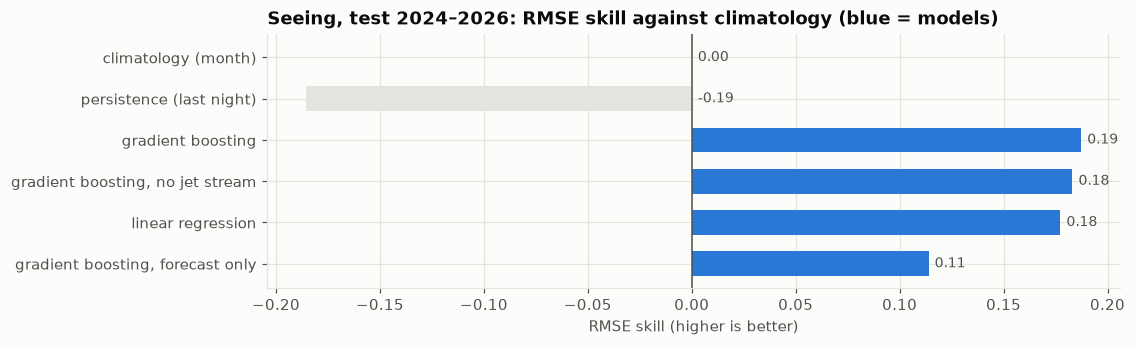

In [8]:
fig, ax = plt.subplots(figsize=(10, 3))
skill_bars(ax, seeing[seeing["inputs"] == "forecast archive"], "rmse_skill_vs_climatology",
           "Seeing, test 2024–2026: RMSE skill against climatology (blue = models)",
           "RMSE skill (higher is better)")
plotting.save(fig, "09_seeing_skill")

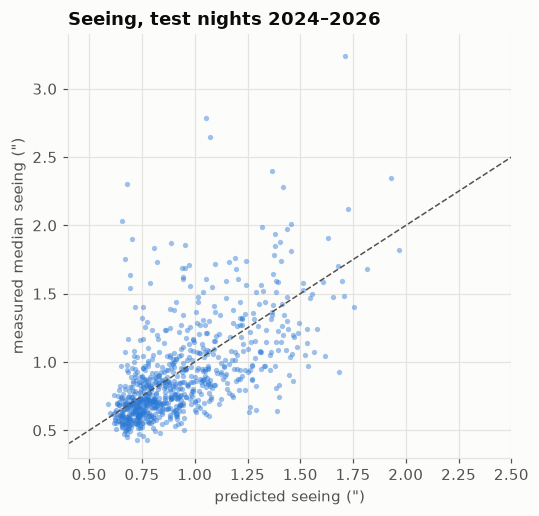

In [9]:
seen = test.dropna(subset=["seeing_median"])
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.scatter(seen["pred_seeing"], seen["seeing_median"], s=12, color=BLUE, alpha=0.45, linewidth=0)
ax.plot([0.4, 2.5], [0.4, 2.5], color=plotting.TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.set_xlim(0.4, 2.5)
ax.set_ylim(0.3, 3.4)
ax.set_xlabel('predicted seeing (")')
ax.set_ylabel('measured median seeing (")')
ax.set_title("Seeing, test nights 2024–2026")
plotting.save(fig, "10_seeing_predicted_vs_measured")

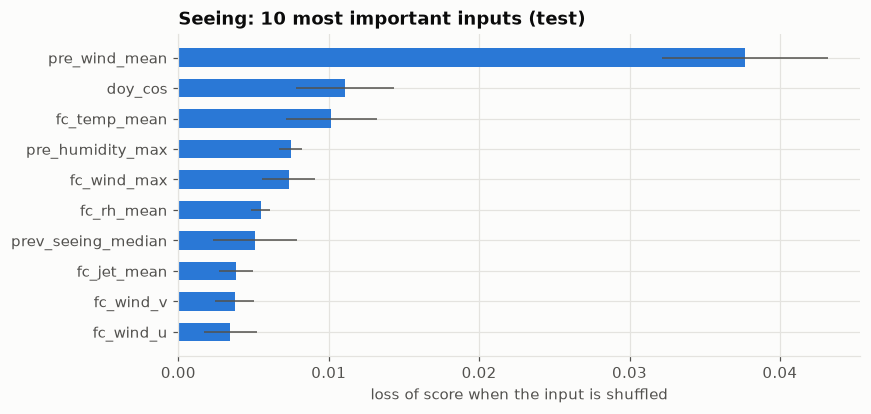

In [10]:
importance_plot("seeing", "Seeing: 10 most important inputs (test)", "11_seeing_importance")

## 3. Hours lost to weather (WHT)

The predicted closure hours are converted to WHT hours with a single factor fitted on the years whose
WHT log is reliable (2017, 2018, 2023) and tested on 2026. 2024–2025 are shown for comparison only: in those
years the WHT books many closed nights as fully observed (EDA section 6), so no model can match them.

In [11]:
lost[["inputs", "method", "nights", "rmse", "mae", "rmse_skill_vs_climatology"]]

,inputs,method,nights,rmse,mae,rmse_skill_vs_climatology
0,reliable test year (2026),"climatology (month, 2010-2018)",299,2.9859,2.0855,0.0000
1,reliable test year (2026),persistence (last night),299,3.2321,1.4213,-0.0824
2,reliable test year (2026),calibrated closure forecast,299,2.6508,1.3634,0.1122
3,suspect years 2024-2025 (comparison only),"climatology (month, 2010-2018)",725,2.6515,2.0853,0.0000
4,suspect years 2024-2025 (comparison only),persistence (last night),725,2.8665,1.2077,-0.0811
5,suspect years 2024-2025 (comparison only),calibrated closure forecast,725,2.9320,1.5464,-0.1058


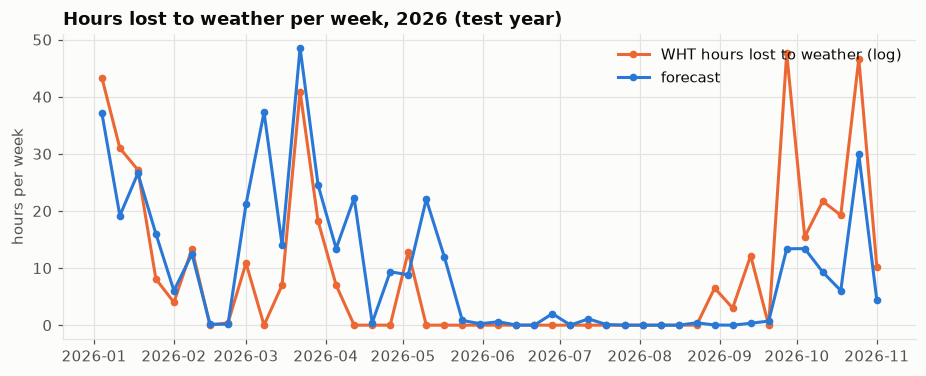

In [12]:
year = predictions[(predictions["year"] == 2026)].dropna(subset=["wht_weather_lost_h"])
weekly = year[["wht_weather_lost_h", "pred_lost_h", "dome_closed_h"]].resample("W").sum()
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(weekly.index, weekly["wht_weather_lost_h"], color=ORANGE, marker="o", markersize=4,
        label="WHT hours lost to weather (log)")
ax.plot(weekly.index, weekly["pred_lost_h"], color=BLUE, marker="o", markersize=4, label="forecast")
ax.set_ylabel("hours per week")
ax.set_title("Hours lost to weather per week, 2026 (test year)")
ax.legend(loc="upper right")
plotting.save(fig, "12_lost_hours_2026")

## 4. With a forecast issued 24 hours earlier

The training archive stitches the first hours of each model run, which is a little better than the forecast
an operator has in the afternoon. Open-Meteo also keeps the forecasts made 24 h before (since 2025): a little
worse than reality. The rows with `inputs = 24 h old forecast` above use those, on 2025–2026 test nights.
The skill barely changes, because most of it comes from the station readings before the night and from the
season; without them (`forecast only`), the forecast still beats every baseline for seeing but loses
against precasting for the dome.

In [13]:
both = pd.concat([closure.assign(target="closure", score=closure["brier_skill_vs_climatology"]),
                  seeing.assign(target="seeing", score=seeing["rmse_skill_vs_climatology"])])
both[both["kind"] == "model"].pivot_table(index=["target", "method"], columns="inputs", values="score").round(3)

inputs                                    24 h old forecast  forecast archive
target  method                                                               
closure gradient boosting                             0.561             0.550
        gradient boosting, forecast only              0.318             0.367
        logistic regression                           0.480             0.480
seeing  gradient boosting                             0.198             0.187
        gradient boosting, forecast only              0.171             0.114
        gradient boosting, no jet stream              0.190             0.183
        linear regression                             0.181             0.177

## Reading the results
- **Dome closure:** gradient boosting gets a Brier skill of 0.55 against climatology, against 0.45 for the best
  reference (precasting: "is it already humid before the night?"). It mostly sharpens precasting with the
  forecast; the station humidity before the night is by far the strongest input. Between 40 % and 90 % the
  probabilities are somewhat too high (reliability diagram): a calibration step is a possible improvement.
- **Seeing:** ~18 % less RMSE than climatology. Wind before the night is the strongest input, as in
  Abárzuza et al. 2025. Good nights are still hard to tell apart: most of the turbulence is above the
  ground layer the station sees.
- **Hours lost:** in 2026 the forecast beats both references (RMSE 2.65 h against 2.99 h for climatology, MAE
  1.36 h against 1.42 h for persistence).
- **Limits:** one site, one forecast model, ~10 years. The labels are a rebuilt rule (closure) and a human
  log (WHT), not the GTC's own decisions.